<a href="https://colab.research.google.com/github/Rohan-724/DSA0404/blob/main/EXP_12_FODS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pdfplumber

from google.colab import files

uploaded = files.upload()

pdf_file = next(iter(uploaded))

print("PDF uploaded successfully:", pdf_file)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 49.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 47.4 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


Saving 12.Temprain.pdf to 12.Temprain.pdf
PDF uploaded successfully: 12.Temprain.pdf


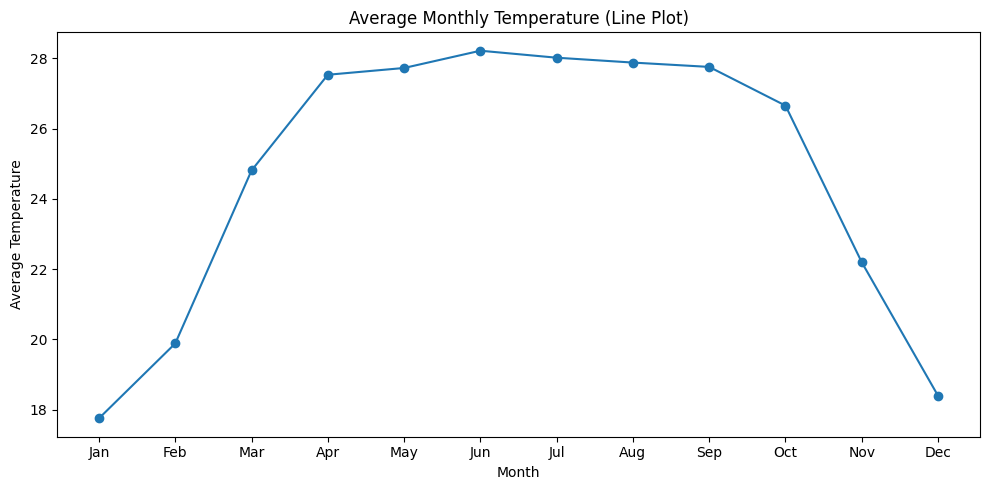

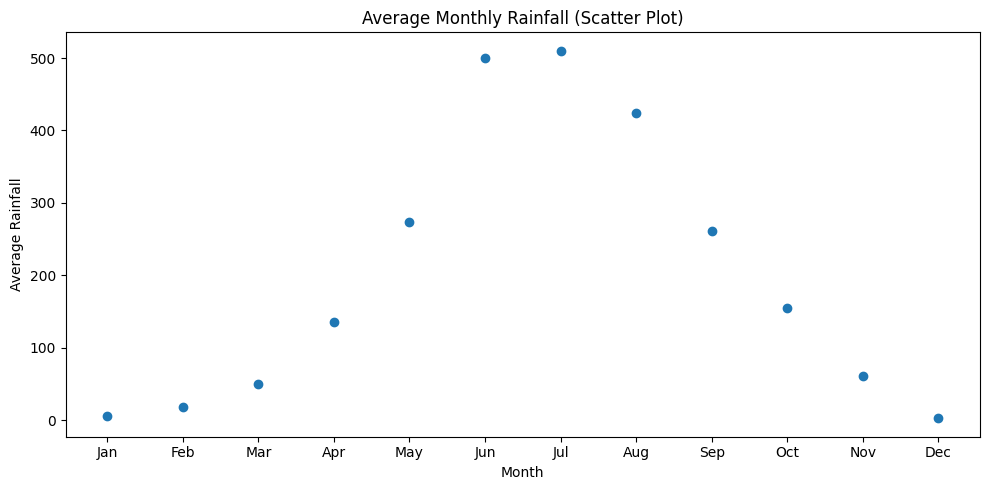

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber

all_data = []

with pdfplumber.open(pdf_file) as pdf:
    for page in pdf.pages:
        tables = page.extract_tables()

        for table in tables:
            if not table or len(table) < 2:
                continue

            headers = [
                str(col).strip().lower() if col else ""
                for col in table[0]
            ]

            if all(col in headers for col in ["tem", "month", "year", "rain"]):
                df = pd.DataFrame(table[1:], columns=headers)
                all_data.append(df[["tem", "month", "year", "rain"]])

if all_data:
    df = pd.concat(all_data, ignore_index=True)

    df["tem"] = pd.to_numeric(df["tem"], errors="coerce")
    df["month"] = pd.to_numeric(df["month"], errors="coerce")
    df["rain"] = pd.to_numeric(df["rain"], errors="coerce")

    df = df.dropna(subset=["tem", "month", "rain"])

    monthly_temp = df.groupby("month")["tem"].mean().sort_index()
    monthly_rain = df.groupby("month")["rain"].mean().sort_index()

    months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    plt.figure(figsize=(10, 5))
    plt.plot(monthly_temp.index, monthly_temp.values, marker='o')
    plt.title("Average Monthly Temperature (Line Plot)")
    plt.xlabel("Month")
    plt.ylabel("Average Temperature")
    plt.xticks(range(1, 13), months)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.scatter(monthly_rain.index, monthly_rain.values)
    plt.title("Average Monthly Rainfall (Scatter Plot)")
    plt.xlabel("Month")
    plt.ylabel("Average Rainfall")
    plt.xticks(range(1, 13), months)
    plt.tight_layout()
    plt.show()

else:
    print("No temperature and rainfall data found.")